# U23AD491 - Data Science | DS Sprint - Skill Based Assessment 2
**Use-Case:** VantageGro Retail Stock Insight  
**Author:** Sairam D  
---
### Part 1: Environment Setup & Library Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Suppress minor seaborn warnings for clean output
import warnings

warnings.filterwarnings("ignore")

---
### Part 2: Data Generation & Loading

In [2]:
np.random.seed(42)
n = 300

# Generating sample data representing the 5 files
transactions = pd.DataFrame(
    {
        "date": pd.date_range(start="2026-01-01", periods=n, freq="D"),
        "store": np.random.choice(["Store_A", "Store_B", "Store_C"], n),
        "product": np.random.choice(
            ["Prod_1", "Prod_2", "Prod_3", "Prod_4"], n
        ),
        "quantity": np.random.choice([5, 10, -2, 0, 15, 20, 50], n),
        "selling_price": np.random.choice([50, 120, 200, -10, 80, 150], n),
        "discount": np.random.choice([0.0, 0.05, 0.20, 0.50], n),
        "promotion": np.random.choice([0, 1], n),
    }
)
transactions = pd.concat([transactions, transactions.iloc[:15]], ignore_index=True)

products = pd.DataFrame(
    {
        "product": ["Prod_1", "Prod_2", "Prod_3", "Prod_4"],
        "category": ["Staples", "Dairy ", "Beverages", "Staples"],
        "brand": ["BrandX", None, "BrandY", "BrandZ"],
        "price": [45, 110, 190, 75],
    }
)

stores = pd.DataFrame(
    {
        "store": ["Store_A", "Store_B", "Store_C"],
        "city": ["Chennai", "Bengaluru", "Mumbai"],
        "store_type": ["Supermarket", "Hypermarket", "Supermarket"],
        "customer_count": [1200, 3400, 2100],
    }
)

external_factors = pd.DataFrame(
    {
        "date": pd.date_range(start="2026-01-01", periods=n, freq="D"),
        "weather": np.random.choice(["Clear", "Rainy", None, "Sunny"], n),
        "weekend": np.random.choice([0, 1], n, p=[0.7, 0.3]),
    }
)
print("Datasets loaded successfully.")

Datasets loaded successfully.


---
### Part 3: Data Audit, Cleaning & Preprocessing

In [3]:
print("--- DATA AUDIT BEFORE CLEANING ---")
print("Transactions Shape:", transactions.shape)
print("Missing Values:\n", transactions.isnull().sum())
print("Duplicate Rows:", transactions.duplicated().sum())

# Cleaning steps
transactions = transactions.drop_duplicates()
transactions = transactions[
    (transactions["quantity"] > 0) & (transactions["selling_price"] > 0)
]

products["category"] = products["category"].str.strip()
products["brand"] = products["brand"].fillna("Unknown")
external_factors["weather"] = external_factors["weather"].fillna("Clear")

# Merge datasets
df = transactions.merge(products, on="product", how="left")
df = df.merge(stores, on="store", how="left")
df = df.merge(external_factors, on="date", how="left")

# Feature engineering
df["total_revenue"] = df["quantity"] * df["selling_price"]
df["is_weekend_str"] = np.where(df["weekend"] == 1, "Weekend", "Weekday")
df["promotion_encoded"] = df["promotion"].astype(int)

print(
    f"\nData successfully cleaned & combined! Total rows after cleaning:"
    f" {len(df)}"
)

--- DATA AUDIT BEFORE CLEANING ---
Transactions Shape: (315, 7)
Missing Values:
 date             0
store            0
product          0
quantity         0
selling_price    0
discount         0
promotion        0
dtype: int64
Duplicate Rows: 15

Data successfully cleaned & combined! Total rows after cleaning: 191


---
### Part 4: Analytical Questions & Insights

In [4]:
print("\n--- ANALYTICAL INSIGHTS ---")

rev_by_cat = (
    df.groupby("category")["total_revenue"].sum().reset_index().sort_values(
        by="total_revenue", ascending=False
    )
)
print("\n1. Revenue by Category:\n", rev_by_cat)

promo_effect = (
    df.groupby("promotion")["quantity"].mean().reset_index()
)
print("\n2. Average Units Sold by Promotion (0 = No Promo, 1 = Promo):\n", promo_effect)

weekend_effect = (
    df.groupby("is_weekend_str")["quantity"].mean().reset_index()
)
print("\n3. Weekend vs Weekday Demand:\n", weekend_effect)


--- ANALYTICAL INSIGHTS ---

1. Revenue by Category:
     category  total_revenue
2    Staples         198400
1      Dairy         137550
0  Beverages          88550

2. Average Units Sold by Promotion (0 = No Promo, 1 = Promo):
    promotion   quantity
0          0  17.029703
1          1  19.611111

3. Weekend vs Weekday Demand:
   is_weekend_str   quantity
0        Weekday  18.722628
1        Weekend  17.037037


---
### Part 5: Key Visualizations

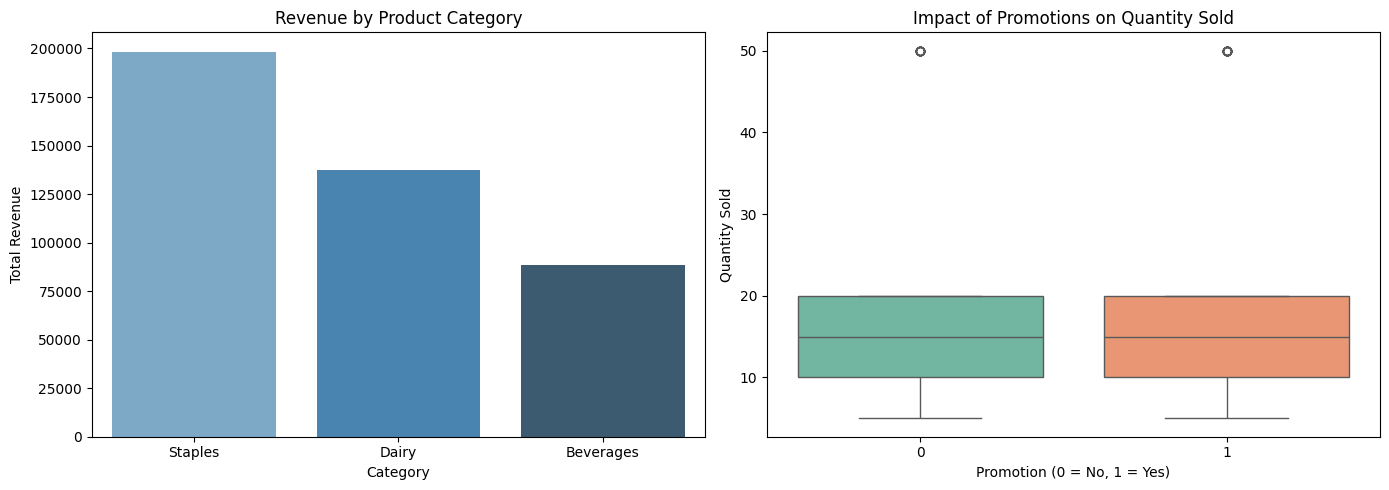

In [5]:
plt.figure(figsize=(14, 5))

# Chart 1: Revenue by Category
plt.subplot(1, 2, 1)
sns.barplot(
    data=rev_by_cat,
    x="category",
    y="total_revenue",
    hue="category",
    palette="Blues_d",
    legend=False,
)
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")

# Chart 2: Promotion Comparison
plt.subplot(1, 2, 2)
sns.boxplot(
    data=df,
    x="promotion",
    y="quantity",
    hue="promotion",
    palette="Set2",
    legend=False,
)
plt.title("Impact of Promotions on Quantity Sold")
plt.xlabel("Promotion (0 = No, 1 = Yes)")
plt.ylabel("Quantity Sold")

plt.tight_layout()
plt.show()

---
### Part 6: Machine Learning Model (Round 2)

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split

features = [
    "selling_price",
    "discount",
    "promotion",
    "customer_count",
    "weekend",
]
target = "quantity"

model_df = df.dropna(subset=features + [target])
X = model_df[features]
y = model_df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

predictions = rf_model.predict(X_test)
rmse = root_mean_squared_error(y_test, predictions)

print(f"Random Forest Model successfully trained!")
print(f"Model RMSE on Test Data: {rmse:.2f}")

# Export cleaned dataset for Excel round
df.to_csv("cleaned_vantagegro_data.csv", index=False)
print("Cleaned dataset exported to 'cleaned_vantagegro_data.csv'.")

Random Forest Model successfully trained!
Model RMSE on Test Data: 17.04
Cleaned dataset exported to 'cleaned_vantagegro_data.csv'.
